# Encoders do DeepDensGNN no Cora — ablação por mrd_k

Compara **GCN, GAT e GraphSAGE** nos resultados de `results/encodertype_cora`.
A grade tem 30 valores (`2, 4, …, 60`) e três seeds (`2026, 2027, 2028`): **270 execuções**.
Use **Restart Kernel and Run All** para atualizar a análise conforme os experimentos terminarem.

**Pergunta:** qual encoder tem melhor desempenho em cada valor de k e no conjunto de valores já comparáveis?
NMI é o critério principal inicial; altere `PRIMARY_METRIC` na próxima célula para explorar outros critérios.
Não há um “melhor” encoder independente da métrica escolhida.

Nesta grade, **mrd_k e hdbscan_min_samples variam juntos**. No DeepDensGNN, `mrd_k` afeta a
seleção adaptativa de suportes; `candidate_k` permanece fixo e define as escalas da MRD aprendida.
Logo, a curva em k mede a variação conjunta dos parâmetros de densidade.
Os encoders têm duas camadas: GAT com uma cabeça e GraphSAGE com agregação pela média.

In [1]:
from pathlib import Path
from itertools import product
from datetime import datetime, timezone
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/configs_encodertype').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Abra o notebook na raiz do repositório ou em scripts/.')
RESULTS = ROOT / 'results/encodertype_cora'
CONFIGS = ROOT / 'configs/configs_encodertype'
EXPORT = RESULTS / 'analysis'
PRIMARY_METRIC = 'nmi'
ENCODERS = ['gcn', 'gat', 'sage']
LABELS = {'gcn': 'GCN', 'gat': 'GAT', 'sage': 'GraphSAGE'}
COLORS = {'gcn': '#0072B2', 'gat': '#D55E00', 'sage': '#009E73'}
TITLES = {'nmi': 'NMI', 'ari': 'ARI', 'acc': 'ACC', 'f1_macro': 'F1 macro',
          'f1_micro': 'F1 micro', 'modularity': 'Modularidade', 'n_clusters': 'Nº de clusters',
          'runtime_seconds': 'Tempo (s)', 'silhouette': 'Silhouette',
          'calinski_harabasz': 'Calinski–Harabasz', 'davies_bouldin': 'Davies–Bouldin'}
METRICS = list(TITLES)
HIGHER_IS_BETTER = {m: m not in ['runtime_seconds', 'davies_bouldin']
                   for m in METRICS if m != 'n_clusters'}
assert PRIMARY_METRIC in HIGHER_IS_BETTER, 'Escolha uma métrica com direção definida.'
LOADER = getattr(yaml, 'CSafeLoader', yaml.SafeLoader)
read_yaml = lambda path: yaml.load(path.read_text(), Loader=LOADER)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
SNAPSHOT = datetime.now(timezone.utc).isoformat()
FIGURES = {}
def show_figure(name, fig):
    fig.tight_layout()
    FIGURES[name] = fig
    plt.show()

print('Leitura em UTC:', SNAPSHOT)
print('Critério principal:', TITLES[PRIMARY_METRIC])

Leitura em UTC: 2026-10-01T17:41:49.391228+00:00
Critério principal: NMI


## 1. Leitura, validação e cobertura

O CSV fornece as métricas; `metadata.yaml` identifica encoder, k, seed e hiperparâmetros efetivamente usados.
Cada execução é comparada ao YAML correspondente da grade. Falhas, arquivos incompletos e configurações
divergentes ficam na auditoria e são excluídos das médias. Não se presume o encoder pelo nome do run.

Se houver repetição da mesma combinação **encoder/k/seed**, fica a execução válida e bem-sucedida
mais recente, sem escolher pelo valor da métrica. As duplicatas descartadas são listadas.

In [2]:
expected = {}
for path in sorted(CONFIGS.glob('*.yaml')):
    cfg = read_yaml(path)
    params = cfg['models']['deep_densgnn']['params']
    key = (params['encoder_type'], int(params['mrd_k']))
    if key in expected:
        raise ValueError(f'Configuração duplicada: {key}')
    assert params['hdbscan_min_samples'] == key[1]
    expected[key] = cfg
K_VALUES = sorted({k for _, k in expected})
assert set(expected) == set(product(ENCODERS, range(2, 61, 2)))
seed_sets = {tuple(range(c['experiment']['seed'], c['experiment']['seed'] + c['experiment']['runs']))
             for c in expected.values()}
assert len(seed_sets) == 1
SEEDS = list(seed_sets.pop())
N_SEEDS = len(SEEDS)
assert N_SEEDS == 3

rows, issues = [], []
run_dirs = sorted((RESULTS / 'runs').glob('*'))
for run_dir in run_dirs:
    if not run_dir.is_dir():
        continue
    csv_path = run_dir / 'metrics.csv'
    try:
        frame = pd.read_csv(csv_path)
        selected = frame.loc[frame['model'].eq('deep_densgnn')]
        if len(selected) != 1:
            raise ValueError(f'Esperada uma linha do modelo; encontradas {len(selected)}')
        row = selected.iloc[0].to_dict()
        meta = read_yaml(run_dir / 'deep_densgnn/metadata.yaml')
        params = meta['model_params']
        encoder, k = params['encoder_type'], int(params['mrd_k'])
        seed = int(row['seed'])
        reasons = []
        cfg = expected.get((encoder, k))
        if cfg is None:
            reasons.append('combinação fora da grade')
        else:
            exp = cfg['experiment']
            wanted = cfg['models']['deep_densgnn']['params']
            if params != wanted:
                reasons.append('hiperparâmetros divergem do YAML da grade')
            if not Path(meta['data_pt']).as_posix().endswith(exp['data_pt']):
                reasons.append('data_pt diverge do Cora configurado')
            if row['dataset'] != exp['dataset'] or meta['dataset'] != exp['dataset']:
                reasons.append('dataset divergente')
            if meta.get('device') != exp['device']:
                reasons.append('dispositivo divergente')
        if seed not in SEEDS or int(meta['seed']) != seed:
            reasons.append('seed divergente/fora da grade')
        if row['run_id'] != run_dir.name or meta['model'] != 'deep_densgnn':
            reasons.append('identificação divergente')
        if meta.get('encoder_type', encoder) != encoder:
            reasons.append('encoder divergente nos metadados')
        if row['status'] != 'success' or meta['status'] != 'success':
            reasons.append(f"status CSV={row['status']}, metadata={meta['status']}; erro={meta.get('error')}")
        row.update(encoder_type=encoder, mrd_k=k, hdbscan_min_samples=params['hdbscan_min_samples'],
                   end_time=meta.get('end_time'), git_commit=meta.get('git_commit'),
                   device=meta.get('device'), run_path=str(run_dir.relative_to(ROOT)),
                   valid=not reasons, exclusion_reason='; '.join(reasons))
        rows.append(row)
        if reasons:
            issues.append({'run_id': run_dir.name, 'reason': '; '.join(reasons)})
    except (OSError, ValueError, TypeError, KeyError, yaml.YAMLError) as exc:
        issues.append({'run_id': run_dir.name, 'reason': str(exc)})

raw = pd.DataFrame(rows)
audit = pd.DataFrame(issues, columns=['run_id', 'reason'])
if raw.empty or not raw['valid'].any():
    display(audit)
    raise RuntimeError('Ainda não há execuções válidas; confira a auditoria e execute novamente depois.')
valid = raw.loc[raw['valid']].copy()
valid['end_time'] = pd.to_datetime(valid['end_time'], utc=True, errors='coerce')
valid = valid.sort_values(['end_time', 'run_id'], na_position='first')
keys = ['encoder_type', 'mrd_k', 'seed']
duplicate_mask = valid.duplicated(keys, keep='last')
duplicates = valid.loc[duplicate_mask].copy()
data = valid.loc[~duplicate_mask].copy()
for metric in METRICS:
    data[metric] = pd.to_numeric(data.get(metric, np.nan), errors='coerce').replace([np.inf, -np.inf], np.nan)
data = data.sort_values(['mrd_k', 'encoder_type', 'seed']).reset_index(drop=True)

index = pd.MultiIndex.from_product([K_VALUES, ENCODERS], names=['mrd_k', 'encoder_type'])
coverage = data.groupby(['mrd_k', 'encoder_type']).size().reindex(index, fill_value=0).unstack()
coverage = coverage.reindex(columns=ENCODERS)
missing = pd.DataFrame([
    {'mrd_k': k, 'encoder_type': encoder, 'missing_seed': seed}
    for k, encoder, seed in product(K_VALUES, ENCODERS, SEEDS)
    if not ((data.mrd_k == k) & (data.encoder_type == encoder) & (data.seed == seed)).any()
])
print(f'{len(data)}/270 execuções válidas e únicas; {len(audit)} ocorrências na auditoria; '
      f'{len(duplicates)} duplicatas descartadas.')
display(coverage.rename(columns=LABELS).style.background_gradient(cmap='Blues', vmin=0, vmax=N_SEEDS))
if not audit.empty:
    display(audit)
if not duplicates.empty:
    display(duplicates[['run_id', *keys, 'end_time']])
print('Commits encontrados:', data.git_commit.dropna().unique().tolist())
if data.git_commit.nunique() > 1:
    warnings.warn('Há múltiplos commits; confira se a implementação mudou entre execuções.')
print('Seeds esperadas:', SEEDS, '| combinações completas:', int((coverage == N_SEEDS).sum().sum()), '/90')

270/270 execuções válidas e únicas; 0 ocorrências na auditoria; 0 duplicatas descartadas.


encoder_type,GCN,GAT,GraphSAGE
mrd_k,,,
2,3,3,3
4,3,3,3
6,3,3,3
8,3,3,3
10,3,3,3
12,3,3,3
14,3,3,3
16,3,3,3
18,3,3,3


Commits encontrados: ['bd294f0bab45a96742043d797656d463208aeb5c']
Seeds esperadas: [2026, 2027, 2028] | combinações completas: 90 /90


## 2. Curvas por k: desempenho, estrutura e custo

Linhas e faixas mostram **média ± desvio padrão amostral** entre as três seeds, apenas para combinações
completas naquela métrica. Círculos vazios mostram médias parciais (1–2 seeds), que não entram nos rankings.
As faixas descrevem dispersão; não são intervalos de confiança nem testes de significância.
Número de clusters é descritivo, sem uma direção universal de melhora.

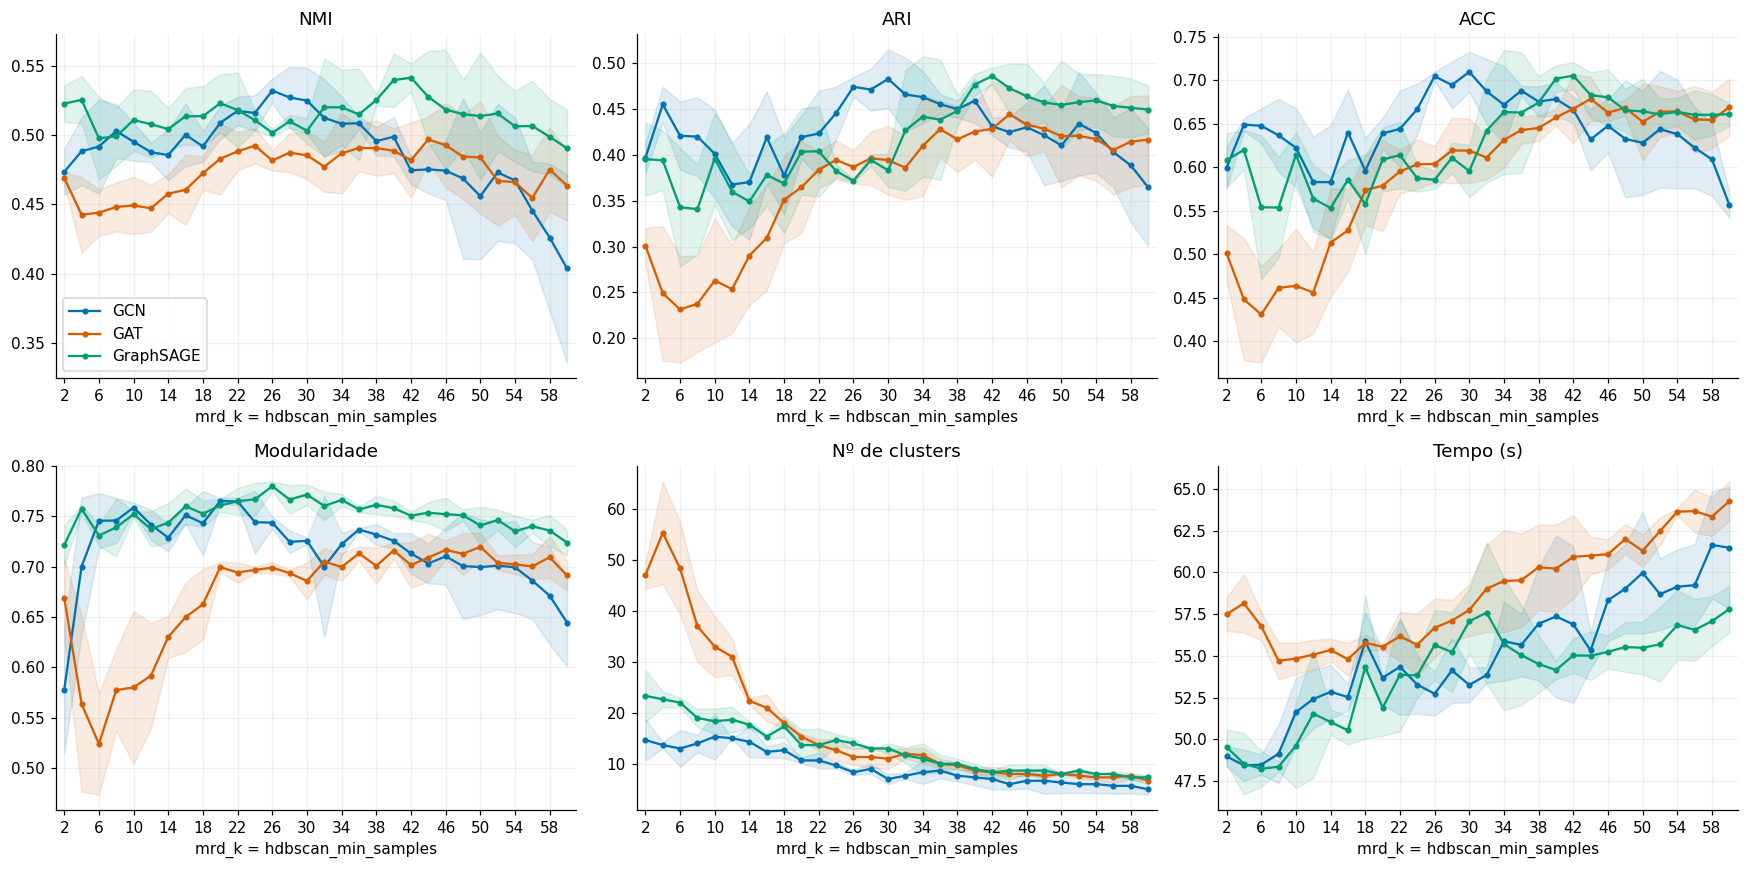

In [3]:
long = data.melt(id_vars=['run_id', 'encoder_type', 'mrd_k', 'seed'],
                 value_vars=METRICS, var_name='metric', value_name='value')
summary = long.groupby(['encoder_type', 'mrd_k', 'metric'])['value'].agg(['mean', 'std', 'count']).reset_index()
summary['complete'] = summary['count'].eq(N_SEEDS)

def plot_curves(metrics, name):
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), squeeze=False)
    for ax, metric in zip(axes.flat, metrics):
        for encoder in ENCODERS:
            sub = summary[(summary.encoder_type == encoder) & (summary.metric == metric)].set_index('mrd_k').reindex(K_VALUES)
            means = sub['mean'].where(sub['complete'].fillna(False))
            std = sub['std'].where(sub['complete'].fillna(False))
            ax.plot(K_VALUES, means, 'o-', ms=3, color=COLORS[encoder], label=LABELS[encoder])
            ax.fill_between(K_VALUES, means - std, means + std, color=COLORS[encoder], alpha=.12)
            partial = sub[(sub['count'] > 0) & (sub['count'] < N_SEEDS)]
            ax.scatter(partial.index, partial['mean'], facecolors='none', edgecolors=COLORS[encoder], s=45)
        ax.set(title=TITLES[metric], xlabel='mrd_k = hdbscan_min_samples', xticks=range(2, 61, 4))
        ax.set_xlim(1, 61)
    for ax in list(axes.flat)[len(metrics):]:
        ax.set_visible(False)
    axes.flat[0].legend()
    show_figure(name, fig)

plot_curves(['nmi', 'ari', 'acc', 'modularity', 'n_clusters', 'runtime_seconds'], 'curvas_principais')

F1 e métricas internas complementam a análise. Silhouette, Calinski–Harabasz e Davies–Bouldin são
calculados nos embeddings de cada encoder: os espaços diferem, portanto esses índices não substituem
NMI/ARI para comparar recuperação das classes. Davies–Bouldin e tempo: menor é melhor.

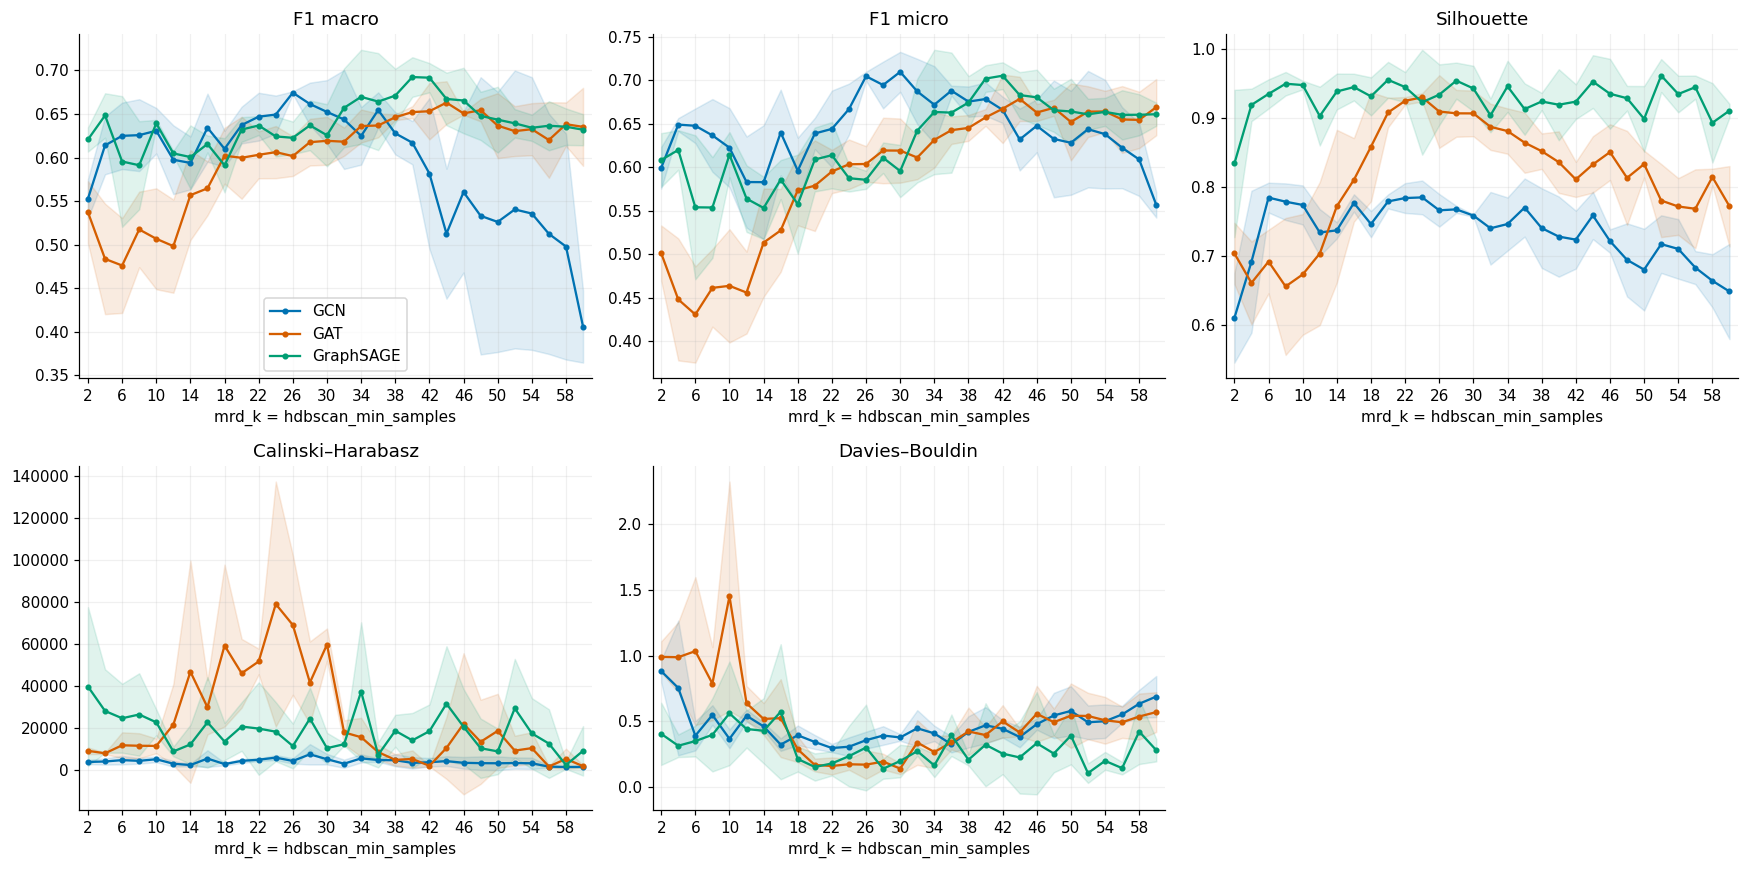

In [4]:
plot_curves(['f1_macro', 'f1_micro', 'silhouette', 'calinski_harabasz', 'davies_bouldin'], 'curvas_complementares')

## 3. Melhor encoder em cada k

A tabela de vencedores usa apenas k com **três seeds para cada um dos três encoders** na métrica principal.
A coluna de diferença é a vantagem da média vencedora sobre a segunda colocada (na direção de melhora).
Empates numéricos são explicitados. O mapa mostra também combinações completas de k que ainda não têm
os outros encoders completos; células cinzas indicam ausência de três valores válidos.

Valores de k comparáveis entre os três encoders: [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60]


,mrd_k,winner,best_mean,advantage_over_second,GCN,GAT,GraphSAGE
0,2,GraphSAGE,0.522772,0.049255,0.4735 ± 0.0166,0.4692 ± 0.0044,0.5228 ± 0.0132
1,4,GraphSAGE,0.525485,0.037145,0.4883 ± 0.0245,0.4424 ± 0.0272,0.5255 ± 0.0171
2,6,GraphSAGE,0.497715,0.005948,0.4918 ± 0.0340,0.4440 ± 0.0168,0.4977 ± 0.0296
3,8,GCN,0.502875,0.003772,0.5029 ± 0.0194,0.4481 ± 0.0177,0.4991 ± 0.0212
4,10,GraphSAGE,0.510896,0.015676,0.4952 ± 0.0138,0.4492 ± 0.0207,0.5109 ± 0.0221
5,12,GraphSAGE,0.507903,0.020189,0.4877 ± 0.0071,0.4472 ± 0.0169,0.5079 ± 0.0241
6,14,GraphSAGE,0.504374,0.018819,0.4856 ± 0.0181,0.4577 ± 0.0140,0.5044 ± 0.0152
7,16,GraphSAGE,0.513666,0.013359,0.5003 ± 0.0226,0.4605 ± 0.0254,0.5137 ± 0.0202
8,18,GraphSAGE,0.513684,0.021868,0.4918 ± 0.0112,0.4726 ± 0.0121,0.5137 ± 0.0218
9,20,GraphSAGE,0.523028,0.014060,0.5090 ± 0.0119,0.4829 ± 0.0257,0.5230 ± 0.0210


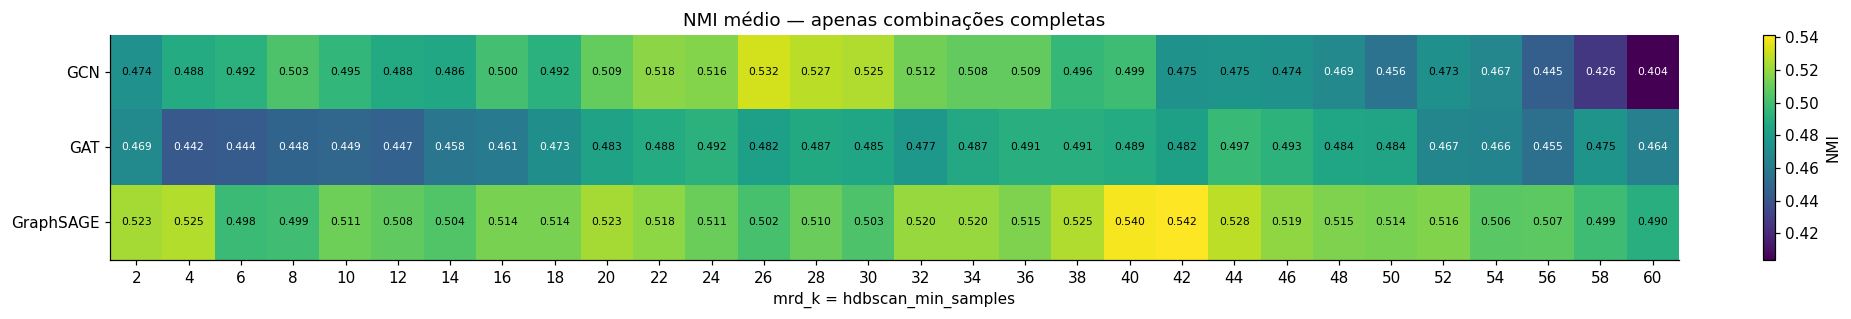

In [5]:
primary = summary[summary.metric.eq(PRIMARY_METRIC) & summary.complete].copy()
means = primary.pivot(index='mrd_k', columns='encoder_type', values='mean').reindex(index=K_VALUES, columns=ENCODERS)
stds = primary.pivot(index='mrd_k', columns='encoder_type', values='std').reindex(index=K_VALUES, columns=ENCODERS)
common_k = means.dropna().index.tolist()
higher = HIGHER_IS_BETTER[PRIMARY_METRIC]
direction = 1 if higher else -1
winner_rows = []
for k in common_k:
    ordered = means.loc[k].sort_values(ascending=not higher)
    best = ordered.iloc[0]
    tied = ordered.index[np.isclose(ordered.to_numpy(), best, rtol=0, atol=1e-12)].tolist()
    row = {'mrd_k': k, 'winner': ' / '.join(LABELS[e] for e in tied),
           'best_mean': best, 'advantage_over_second': direction * (best - ordered.iloc[1])}
    for encoder in ENCODERS:
        row[LABELS[encoder]] = f'{means.loc[k, encoder]:.4f} ± {stds.loc[k, encoder]:.4f}'
    winner_rows.append(row)
winners = pd.DataFrame(winner_rows)
print(f'Valores de k comparáveis entre os três encoders: {common_k}')
if not winners.empty:
    display(winners)
else:
    print('Aguardando pelo menos um k com três seeds válidas por encoder.')

fig, ax = plt.subplots(figsize=(17, 3))
cmap = plt.get_cmap('viridis' if higher else 'viridis_r').copy()
cmap.set_bad('#dddddd')
values = means.T.to_numpy(dtype=float)
im = ax.imshow(np.ma.masked_invalid(values), aspect='auto', cmap=cmap)
ax.set(xticks=range(len(K_VALUES)), xticklabels=K_VALUES,
       yticks=range(3), yticklabels=[LABELS[e] for e in ENCODERS],
       xlabel='mrd_k = hdbscan_min_samples', title=f'{TITLES[PRIMARY_METRIC]} médio — apenas combinações completas')
ax.grid(False)
for i, j in product(range(3), range(len(K_VALUES))):
    if np.isfinite(values[i, j]):
        color = 'white' if im.norm(values[i, j]) < .5 else 'black'
        if not higher:
            color = 'black' if im.norm(values[i, j]) < .5 else 'white'
        ax.text(j, i, f'{values[i, j]:.3f}', ha='center', va='center', fontsize=7, color=color)
fig.colorbar(im, ax=ax, label=TITLES[PRIMARY_METRIC], fraction=.025)
show_figure('mapa_metrica_principal', fig)

## 4. Ranking geral e melhores combinações observadas

O ranking geral usa **os mesmos k completos e as mesmas seeds para todos os encoders**. Primeiro calcula
a média sobre k para cada seed; depois resume essas três médias. O desvio padrão abaixo é entre médias
por seed, não considera cada k como uma nova repetição independente. Rank 1 é o melhor; empates recebem
rank médio. Esta é uma comparação descritiva da grade observada, sem teste estatístico de superioridade.

A tabela de melhores combinações permite escolher um k por encoder e informa o número de k completos
avaliados: encoders com mais k disponíveis tiveram mais oportunidades de obter um máximo.

In [6]:
overall = pd.DataFrame()
if common_k:
    balanced = data[data.mrd_k.isin(common_k)]
    per_seed = balanced.groupby(['encoder_type', 'seed'])[PRIMARY_METRIC].mean()
    overall = per_seed.groupby('encoder_type').agg(mean='mean', std_between_seed_means='std').reindex(ENCODERS)
    overall['mean_rank'] = means.loc[common_k].rank(axis=1, ascending=not higher, method='average').mean()
    overall['complete_k'] = len(common_k)
    overall = overall.sort_values('mean', ascending=not higher)
    display(overall.rename(index=LABELS))

best_per_encoder = primary.sort_values(['mean', 'mrd_k'], ascending=[not higher, True]).groupby('encoder_type', sort=False).head(1)
best_per_encoder = best_per_encoder.merge(primary.groupby('encoder_type').size().rename('evaluated_k'), on='encoder_type')
display(best_per_encoder[['encoder_type', 'mrd_k', 'mean', 'std', 'count', 'evaluated_k']])
print('As dez melhores combinações completas observadas:')
display(primary.sort_values(['mean', 'mrd_k'], ascending=[not higher, True]).head(10)[
    ['encoder_type', 'mrd_k', 'mean', 'std', 'count']])

,mean,std_between_seed_means,mean_rank,complete_k
encoder_type,,,,
GraphSAGE,0.513901,0.007097,1.166667,30
GCN,0.487741,0.008585,2.100000,30
GAT,0.473656,0.016945,2.733333,30


,encoder_type,mrd_k,mean,std,count,evaluated_k
0,sage,42,0.541535,0.010277,3,30
1,gcn,26,0.532144,0.008800,3,30
2,gat,44,0.496905,0.016315,3,30


As dez melhores combinações completas observadas:


,encoder_type,mrd_k,mean,std,count
888,sage,42,0.541535,0.010277,3
877,sage,40,0.539710,0.019301,3
470,gcn,26,0.532144,0.008800,3
899,sage,44,0.527630,0.033192,3
481,gcn,28,0.527254,0.022071,3
679,sage,4,0.525485,0.017057,3
866,sage,38,0.525289,0.004027,3
492,gcn,30,0.524914,0.023669,3
767,sage,20,0.523028,0.020953,3
668,sage,2,0.522772,0.013224,3


## 5. Diferenças pareadas em relação ao GCN

Para cada k, subtrai-se o GCN do outro encoder **na mesma seed**. Os gráficos mostram a média e o
desvio padrão dessas três diferenças. Valores positivos favorecem o outro encoder em NMI/ARI/ACC;
para tempo e Davies–Bouldin, valores negativos favorecem o outro encoder.
Pareamento usa `(mrd_k, seed)`, pois os run IDs são distintos entre os encoders.

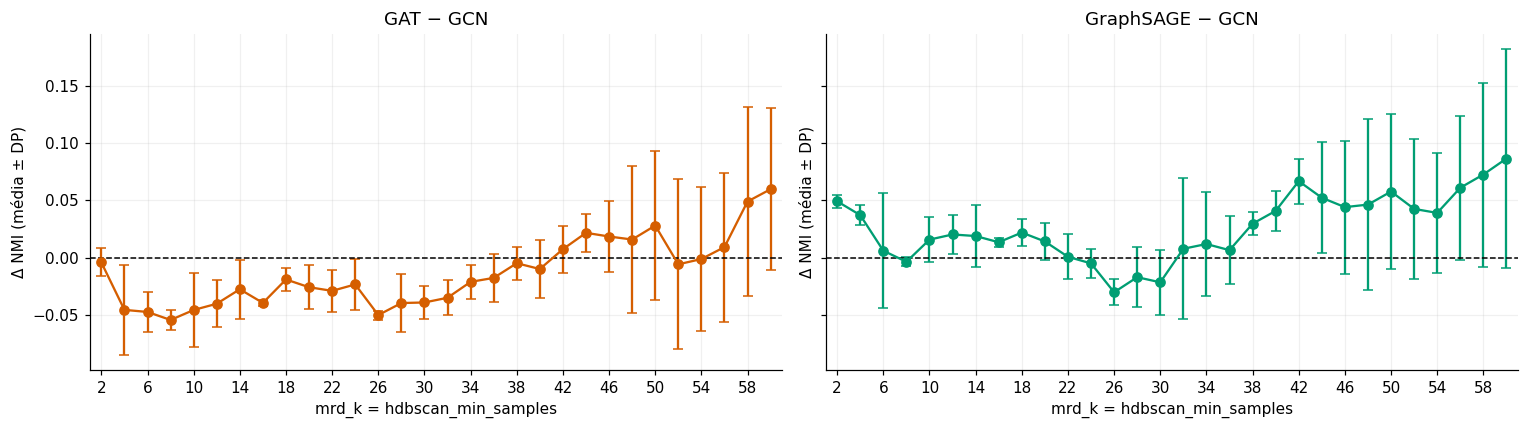

In [7]:
paired_rows = []
reference = data[data.encoder_type.eq('gcn')][['mrd_k', 'seed', PRIMARY_METRIC]]
for encoder in ['gat', 'sage']:
    other = data[data.encoder_type.eq(encoder)][['mrd_k', 'seed', PRIMARY_METRIC]]
    pair = other.merge(reference, on=['mrd_k', 'seed'], suffixes=('_other', '_gcn'), validate='one_to_one')
    pair['difference'] = pair[f'{PRIMARY_METRIC}_other'] - pair[f'{PRIMARY_METRIC}_gcn']
    pair['encoder_type'] = encoder
    paired_rows.append(pair[['encoder_type', 'mrd_k', 'seed', 'difference']])
paired = pd.concat(paired_rows, ignore_index=True)
paired_summary = paired.groupby(['encoder_type', 'mrd_k']).difference.agg(['mean', 'std', 'count']).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, encoder in zip(axes, ['gat', 'sage']):
    sub = paired_summary[(paired_summary.encoder_type == encoder) & (paired_summary['count'] == N_SEEDS)]
    ax.errorbar(sub.mrd_k, sub['mean'], yerr=sub['std'], fmt='o-', color=COLORS[encoder], capsize=3)
    ax.axhline(0, color='black', lw=1, linestyle='--')
    ax.set(title=f'{LABELS[encoder]} − GCN', xlabel='mrd_k = hdbscan_min_samples',
           ylabel=f'Δ {TITLES[PRIMARY_METRIC]} (média ± DP)', xlim=(1, 61), xticks=range(2, 61, 4))
show_figure('diferencas_pareadas', fig)

## 6. Logits da MMSRD na melhor execução de cada encoder

Aqui selecionamos a **execução individual de maior NMI de cada encoder**, entre todos os runs
válidos auditados, inclusive repetições da mesma combinação. Isso é diferente da melhor **média de três seeds**
das seções anteriores. A seleção sempre usa **NMI**, mesmo que `PRIMARY_METRIC` seja alterada.
Empates são resolvidos por menor `mrd_k`, menor seed e run ID em ordem crescente.
É uma inspeção exploratória dos melhores casos, não uma estimativa do desempenho típico.

Os arquivos atuais guardam `algorithm.density_scale_info.pi`, `candidate_k`, `cluster_labels`
e `k_eff`, mas **não guardam os logits brutos**. Como

$
\pi_{j,s}=\operatorname{softmax}(\ell_{j,s}/T),\qquad
\widetilde{\ell}_{j,s}=T\left[\log\pi_{j,s}
-\frac{1}{S}\sum_{r=1}^{S}\log\pi_{j,r}\right],
$

podemos reconstruir os **logits centrados por cluster**, equivalentes a
$\ell_{j,s}-\operatorname{média}_r\ell_{j,r}$, até a precisão dos pesos salvos.
Não é possível recuperar o deslocamento absoluto: somar uma constante a todos os logits de um
cluster mantém o mesmo softmax. O notebook verifica que aplicar softmax aos valores reconstruídos
reproduz os pesos salvos; probabilidades zero ou inválidas são reportadas, sem inventar logits finitos.

- **Mapa superior:** logits centrados reconstruídos, em escala de cores comum aos encoders.
- **Mapa inferior:** pesos de mistura $\pi$ salvos, também em escala comum.
- As colunas são **candidate_k** (escalas da MRD), não o `mrd_k` usado na seleção de suportes.
- Cada linha é um cluster HDBSCAN do run escolhido, ordenado por `k_eff`.
  IDs de clusters são locais a cada run e não identificam o mesmo grupo entre encoders.
- `k_eff = Σ π × candidate_k` resume a mistura; não é uma escolha discreta de k.

Os valores são do estado final salvo. Clusters criados no último refresh podem ter pesos uniformes,
sem uma etapa posterior de treino; pesos uniformes não provam ausência de aprendizagem durante todo o run.

In [8]:
# Usa todas as execuções válidas da auditoria, não só as retidas após deduplicação.
nmi_runs = valid.copy()
nmi_runs['nmi'] = pd.to_numeric(nmi_runs['nmi'], errors='coerce')
nmi_runs = nmi_runs[np.isfinite(nmi_runs['nmi'])]
best_nmi_runs = (nmi_runs.sort_values(['nmi', 'mrd_k', 'seed', 'run_id'],
                                    ascending=[False, True, True, True])
                .groupby('encoder_type', sort=False).head(1)
                .set_index('encoder_type').reindex(ENCODERS).dropna(subset=['run_id']))
display(best_nmi_runs[['mrd_k', 'seed', 'nmi', 'run_id']].rename(index=LABELS))


def recover_centered_logits(probabilities, temperature):
    pi = np.asarray(probabilities, dtype=float)
    if pi.ndim != 2 or min(pi.shape) < 1:
        raise ValueError('Matriz pi ausente ou com dimensões inválidas.')
    if not np.isfinite(pi).all() or (pi <= 0).any():
        raise ValueError('Pi contém zeros/valores inválidos: logits finitos não são recuperáveis.')
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError('Temperatura inválida.')
    np.testing.assert_allclose(pi.sum(axis=1), 1.0, rtol=1e-5, atol=1e-7)
    log_pi = np.log(pi)
    centered = temperature * (log_pi - log_pi.mean(axis=1, keepdims=True))
    scores = centered / temperature
    restored = np.exp(scores - scores.max(axis=1, keepdims=True))
    restored /= restored.sum(axis=1, keepdims=True)
    np.testing.assert_allclose(restored, pi, rtol=1e-5, atol=1e-7)
    np.testing.assert_allclose(centered.mean(axis=1), 0.0, atol=1e-12)
    return pi, centered


scale_views, scale_rows, cluster_rows, scale_errors = {}, [], [], []
for encoder, row in best_nmi_runs.iterrows():
    metrics_path = ROOT / row['run_path'] / 'deep_densgnn/metrics.json'
    try:
        algorithm = json.loads(metrics_path.read_text())['algorithm']
        if algorithm['encoder_type'] != encoder or int(algorithm['mrd_k']) != int(row['mrd_k']):
            raise ValueError('metrics.json diverge da execução selecionada.')
        info = algorithm['density_scale_info']
        if not info.get('active', False):
            raise ValueError('Mistura de escalas inativa nesta execução.')
        temperature = float(algorithm['density_temperature'])
        pi, centered = recover_centered_logits(info['pi'], temperature)
        candidate_k = np.asarray(info['candidate_k'], dtype=int)
        cluster_labels = np.asarray(info['cluster_labels'], dtype=int)
        if pi.shape != (len(cluster_labels), len(candidate_k)):
            raise ValueError('Dimensões de pi, clusters e candidate_k incompatíveis.')
        if len(set(candidate_k)) != len(candidate_k) or (candidate_k <= 0).any():
            raise ValueError('candidate_k inválido.')
        if len(set(cluster_labels)) != len(cluster_labels):
            raise ValueError('IDs de clusters duplicados.')
        k_eff = pi @ candidate_k
        np.testing.assert_allclose(k_eff, info['k_eff'], rtol=1e-5, atol=1e-5)
        order = np.argsort(k_eff, kind='stable')
        scale_views[encoder] = dict(pi=pi[order], logits=centered[order],
                                    cluster_labels=cluster_labels[order], candidate_k=candidate_k,
                                    k_eff=k_eff[order], temperature=temperature, run=row)
        for j, label in enumerate(cluster_labels):
            cluster_rows.append(dict(encoder_type=encoder, run_id=row['run_id'],
                                     cluster_label=int(label), k_eff=float(k_eff[j]),
                                     most_weighted_candidate_k=int(candidate_k[np.argmax(pi[j])]),
                                     max_pi=float(pi[j].max())))
            for s, k in enumerate(candidate_k):
                scale_rows.append(dict(encoder_type=encoder, run_id=row['run_id'],
                                       seed=int(row['seed']), mrd_k=int(row['mrd_k']), nmi=float(row['nmi']),
                                       cluster_label=int(label), candidate_k=int(k), temperature=temperature,
                                       pi=float(pi[j, s]), centered_logit_reconstructed=float(centered[j, s])))
    except (OSError, KeyError, TypeError, ValueError, AssertionError) as exc:
        # Não substitui silenciosamente o melhor run por outro com NMI inferior.
        scale_errors.append(dict(encoder_type=encoder, run_id=row['run_id'], reason=str(exc)))
scale_values = pd.DataFrame(scale_rows)
cluster_scales = pd.DataFrame(cluster_rows)
scale_audit = pd.DataFrame(scale_errors, columns=['encoder_type', 'run_id', 'reason'])
if not scale_audit.empty:
    display(scale_audit)
print(f'Logits centrados reconstruídos e softmax verificado: {len(scale_views)}/{len(ENCODERS)} encoders.')

,mrd_k,seed,nmi,run_id
encoder_type,,,,
GCN,28,2026,0.552536,20261001_111536_391927_seed2026_run01
GAT,46,2027,0.525279,20261001_124021_206010_seed2027_run02
GraphSAGE,44,2026,0.562478,20261001_123607_639725_seed2026_run01


Logits centrados reconstruídos e softmax verificado: 3/3 encoders.


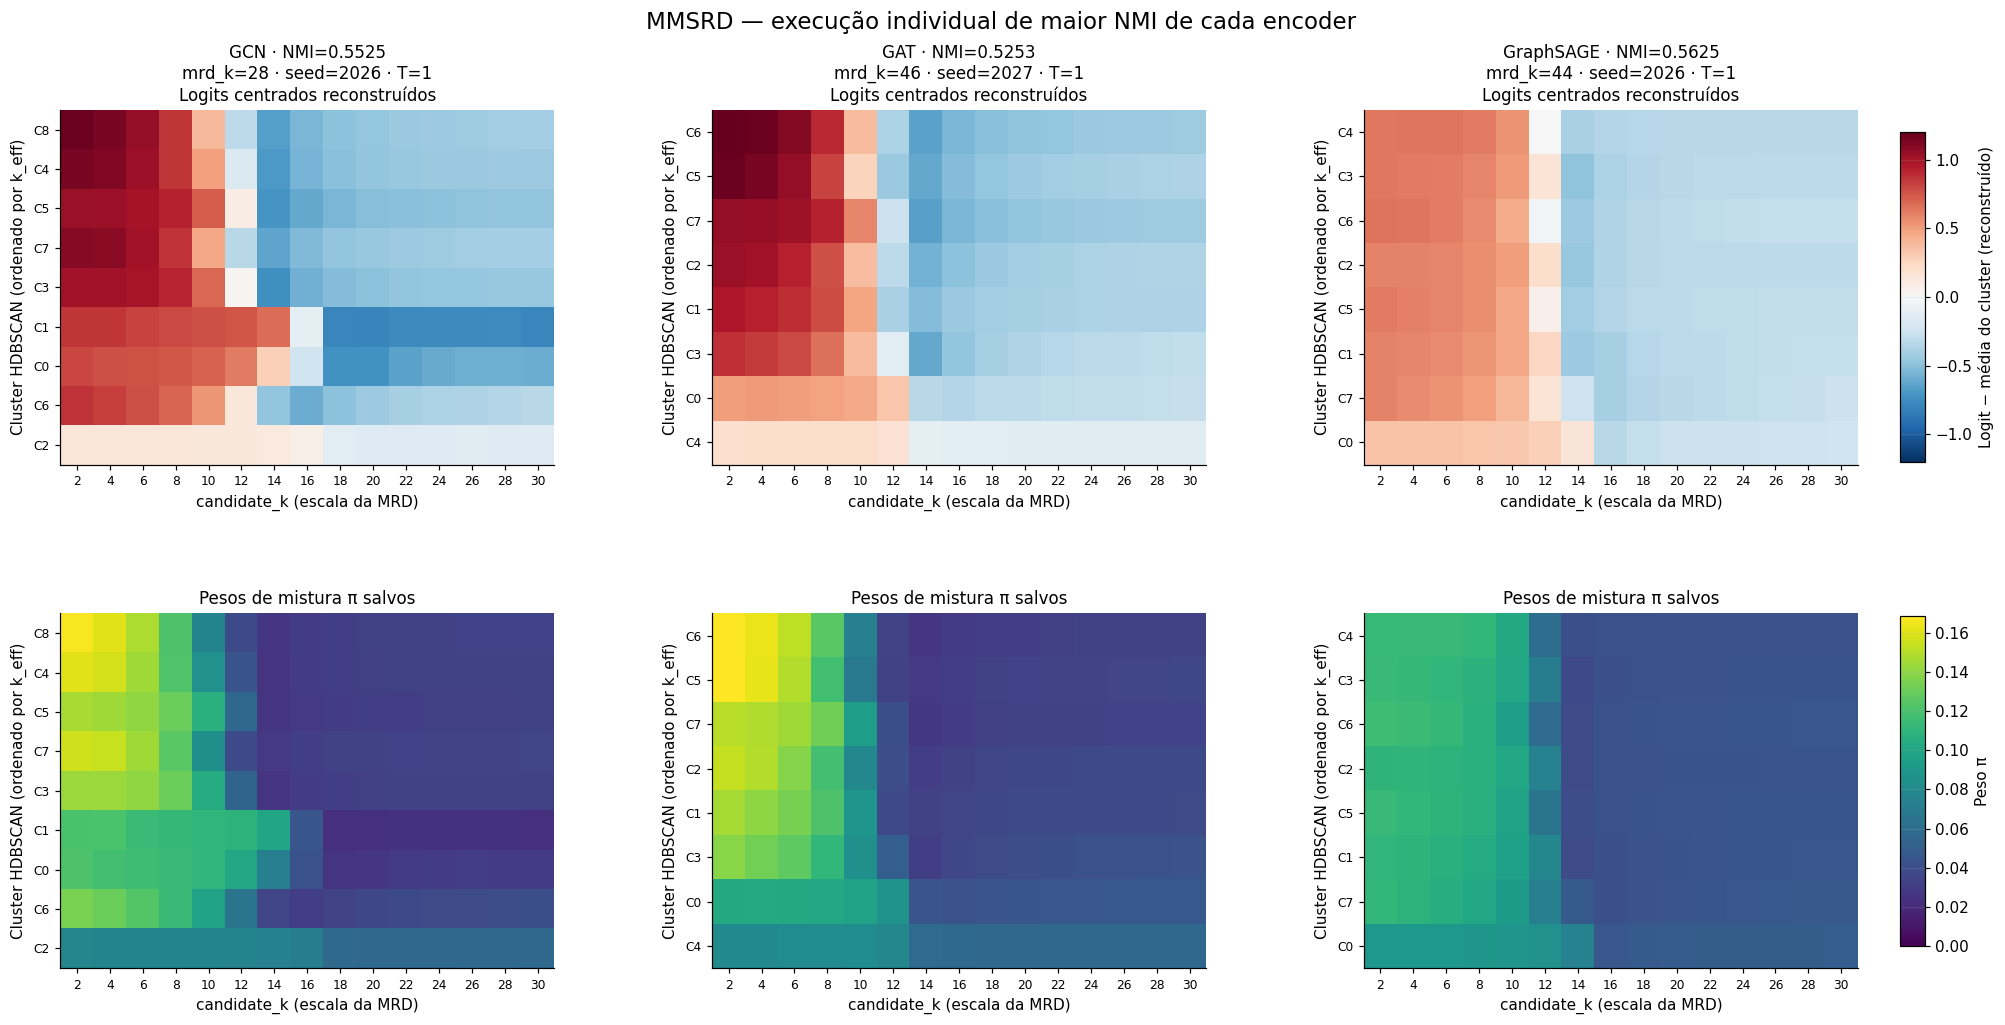

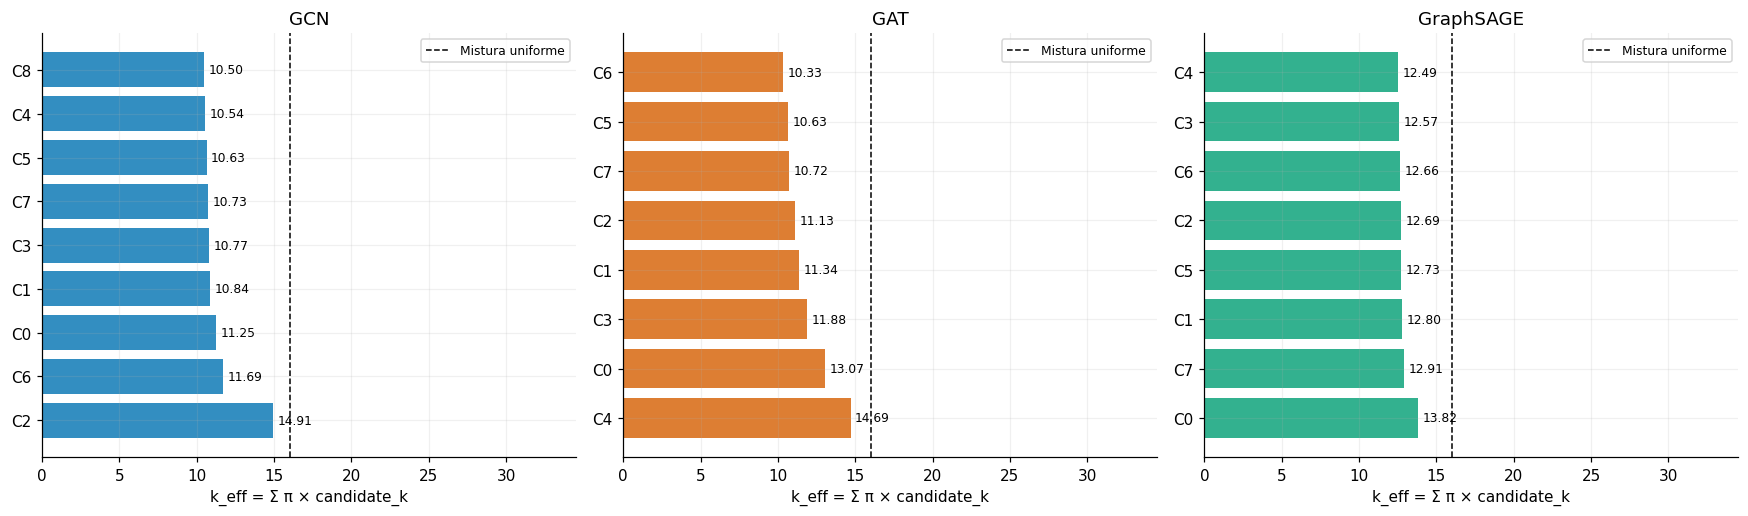

In [9]:
if scale_views:
    # Limites compartilhados: evita aparentar diferenças por autoescala de cada painel.
    limit = max(float(np.abs(v['logits']).max()) for v in scale_views.values())
    limit = limit if limit > 0 else 1e-12
    max_pi = max(float(v['pi'].max()) for v in scale_views.values())
    fig, axes = plt.subplots(2, 3, figsize=(19, 10), squeeze=False)
    fig.subplots_adjust(left=.05, right=.91, top=.88, bottom=.1, wspace=.32, hspace=.42)
    for col, encoder in enumerate(ENCODERS):
        if encoder not in scale_views:
            for ax in axes[:, col]:
                ax.text(.5, .5, f'{LABELS[encoder]}: dados indisponíveis', ha='center', va='center')
                ax.set_axis_off()
            continue
        view = scale_views[encoder]
        row = view['run']
        for r, values in enumerate([view['logits'], view['pi']]):
            ax = axes[r, col]
            if r == 0:
                logit_image = ax.imshow(values, aspect='auto', cmap='RdBu_r', vmin=-limit, vmax=limit)
            else:
                pi_image = ax.imshow(values, aspect='auto', cmap='viridis', vmin=0, vmax=max_pi)
            ax.set(xticks=range(len(view['candidate_k'])), xticklabels=view['candidate_k'],
                   yticks=range(len(view['cluster_labels'])),
                   yticklabels=[f'C{label}' for label in view['cluster_labels']],
                   xlabel='candidate_k (escala da MRD)', ylabel='Cluster HDBSCAN (ordenado por k_eff)')
            ax.tick_params(labelsize=8)
            ax.grid(False)
        axes[0, col].set_title(
            f"{LABELS[encoder]} · NMI={row['nmi']:.4f}\n"
            f"mrd_k={int(row['mrd_k'])} · seed={int(row['seed'])} · T={view['temperature']:g}\n"
            'Logits centrados reconstruídos', fontsize=11)
        axes[1, col].set_title('Pesos de mistura π salvos', fontsize=11)
    fig.colorbar(logit_image, cax=fig.add_axes([.93, .56, .012, .30]), label='Logit − média do cluster (reconstruído)')
    fig.colorbar(pi_image, cax=fig.add_axes([.93, .12, .012, .30]), label='Peso π')
    fig.suptitle('MMSRD — execução individual de maior NMI de cada encoder', fontsize=15, y=.97)
    # O layout reserva duas barras de cores; não aplicar tight_layout aqui.
    FIGURES['mmsrd_logits_melhor_nmi'] = fig
    plt.show()

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
    for ax, encoder in zip(axes, ENCODERS):
        if encoder not in scale_views:
            ax.set_axis_off()
            continue
        view = scale_views[encoder]
        positions = np.arange(len(view['k_eff']))
        ax.barh(positions, view['k_eff'], color=COLORS[encoder], alpha=.8)
        ax.set(yticks=positions, yticklabels=[f'C{label}' for label in view['cluster_labels']],
               xlabel='k_eff = Σ π × candidate_k', title=LABELS[encoder],
               xlim=(0, max(view['candidate_k']) * 1.15))
        ax.invert_yaxis()
        ax.axvline(np.mean(view['candidate_k']), ls='--', color='black', lw=1, label='Mistura uniforme')
        for j, value in enumerate(view['k_eff']):
            ax.text(value + .3, j, f'{value:.2f}', va='center', fontsize=8)
        ax.legend(fontsize=8)
    show_figure('mmsrd_k_eff_melhor_nmi', fig)

# CSVs com todos os valores numéricos para inspecionar os mapas sem arredondamento visual.
EXPORT.mkdir(parents=True, exist_ok=True)
best_nmi_runs[['run_id', 'mrd_k', 'seed', 'nmi', 'run_path']].to_csv(EXPORT / 'mmsrd_melhores_runs_nmi.csv')
scale_values.to_csv(EXPORT / 'mmsrd_logits_centrados_e_pi.csv', index=False)
cluster_scales.to_csv(EXPORT / 'mmsrd_resumo_clusters.csv', index=False)
scale_audit.to_csv(EXPORT / 'mmsrd_auditoria.csv', index=False)

## 7. Leitura automática e exportação

O resumo diferencia o melhor encoder na faixa comum da melhor combinação encoder/k já observada.
Resultados parciais podem mudar quando a grade terminar. As três seeds não bastam, por si só,
para afirmar superioridade estatística; a escolha de k nesta mesma grade também é exploratória.
O notebook não treina modelos nem recalcula métricas. Exporta tabelas e figuras para `analysis/`.

In [10]:
lines = [f'**Snapshot:** {SNAPSHOT}',
         f'**Cobertura:** {len(data)}/270 execuções válidas, '
         f'{int((coverage == N_SEEDS).sum().sum())}/90 combinações com três seeds.',
         f'**Critério:** {TITLES[PRIMARY_METRIC]} ({"maior" if higher else "menor"} é melhor).']
if not overall.empty:
    best_value = overall['mean'].iloc[0]
    leaders = overall.index[np.isclose(overall['mean'], best_value, rtol=0, atol=1e-12)]
    lines.append(f'**Melhor média na faixa comum ({len(common_k)} valores de k):** '
                 + ' / '.join(LABELS[e] for e in leaders) + f', média {best_value:.4f}.')
if not primary.empty:
    best_value = primary['mean'].max() if higher else primary['mean'].min()
    leaders = primary[np.isclose(primary['mean'], best_value, rtol=0, atol=1e-12)]
    for row in leaders.itertuples():
        lines.append(f'**Melhor combinação completa observada:** {LABELS[row.encoder_type]}, '
                     f'k={row.mrd_k}, {TITLES[PRIMARY_METRIC]}={row.mean:.4f} ± {row.std:.4f} (DP, n=3).')
if len(data) < 270:
    lines.append('**Análise parcial:** atualize o notebook quando novas execuções terminarem.')
lines.append('A variação em k altera simultaneamente mrd_k e hdbscan_min_samples; '
             'candidate_k permanece fixo. As conclusões são descritivas.')
report = '\n\n'.join(lines)
display(Markdown(report))

EXPORT.mkdir(parents=True, exist_ok=True)
for name, frame in {'runs_validos': data, 'auditoria': audit, 'duplicatas_descartadas': duplicates,
                    'seeds_faltantes': missing, 'resumo_metricas': summary, 'vencedores_por_k': winners,
                    'melhor_k_por_encoder': best_per_encoder, 'diferencas_pareadas': paired,
                    'resumo_diferencas_pareadas': paired_summary}.items():
    frame.to_csv(EXPORT / f'{name}.csv', index=False)
coverage.to_csv(EXPORT / 'cobertura.csv')
overall.to_csv(EXPORT / 'ranking_faixa_comum.csv')
(EXPORT / 'resumo.md').write_text(report + '\n')
(EXPORT / 'analise_config.json').write_text(json.dumps(
    {'snapshot_utc': SNAPSHOT, 'primary_metric': PRIMARY_METRIC, 'seeds': SEEDS,
     'common_k': common_k, 'valid_runs': len(data), 'expected_runs': 270,
     'duplicate_policy': 'latest_valid_success_per_encoder_k_seed'}, indent=2))
for name, fig in FIGURES.items():
    fig.savefig(EXPORT / f'{name}.png', dpi=180, bbox_inches='tight')
    fig.savefig(EXPORT / f'{name}.svg', bbox_inches='tight')
print('Tabelas, resumo e figuras exportados para:', EXPORT.relative_to(ROOT))

**Snapshot:** 2026-10-01T17:41:49.391228+00:00

**Cobertura:** 270/270 execuções válidas, 90/90 combinações com três seeds.

**Critério:** NMI (maior é melhor).

**Melhor média na faixa comum (30 valores de k):** GraphSAGE, média 0.5139.

**Melhor combinação completa observada:** GraphSAGE, k=42, NMI=0.5415 ± 0.0103 (DP, n=3).

A variação em k altera simultaneamente mrd_k e hdbscan_min_samples; candidate_k permanece fixo. As conclusões são descritivas.

Tabelas, resumo e figuras exportados para: results/encodertype_cora/analysis
